
### 1. Importing Required Libraries

- **Pandas and NumPy:** Data manipulation and numerical operations.
- **Matplotlib and Seaborn:** Data visualization.
- **StandardScaler:** Standardizes numerical features.
- **KMeans and AgglomerativeClustering:** Perform clustering.
- **Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index:** Evaluate clustering quality.
- **PCA and t-SNE:** Reduce dimensions for cluster visualization.
- **Linkage and Dendrogram:** Support hierarchical clustering and its visualization.
- **Warnings:** Suppresses warning messages.
- **RANDOM_STATE = 42:** Helps ensure reproducible results when used by algorithms.


In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Clustering algorithms
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering
)

# Clustering evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Dimensionality reduction / visualization
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Hierarchical clustering visualization and linkage
from scipy.cluster.hierarchy import (
    dendrogram,
    linkage
)

# Warnings
import warnings
warnings.filterwarnings("ignore")


# Reproducibility
RANDOM_STATE = 42

print("All modules imported successfully.")

All modules imported successfully.


In [5]:
df = pd.read_csv(
    '../data/raw/2019-Oct.csv'
)

### 2. Basic Data Inspection

- **Shape and Columns:** Checks the dataset size and column names.
- **First 5 Rows:** Displays sample records.
- **Data Types:** Identifies the type of each column.
- **Missing Values and Duplicates:** Checks data quality.
- **Statistical Summary:** Summarizes numerical features.
- **Event Distribution:** Counts occurrences of each event type.
- **Unique Values:** Counts distinct users, sessions, products, categories, and brands.
- **Price Summary:** Examines the distribution of product prices.
- **Event Time Conversion:** Converts `event_time` to datetime format, handling invalid values as missing.

In [ ]:

# Basic Inspection
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

# Data Types
print("\nData Types:")
print(df.dtypes)

# Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate Rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical Summary
print("\nNumerical Summary:")
display(df.describe())

# Event Distribution
print("\nEvent Types:")
print(df["event_type"].value_counts())

# Unique Values
print("\nUnique Users:", df["user_id"].nunique())
print("Unique Sessions:", df["user_session"].nunique())
print("Unique Products:", df["product_id"].nunique())
print("Unique Categories:", df["category_id"].nunique())
print("Unique Brands:", df["brand"].nunique())

# Price Check
print("\nPrice Summary:")
display(df["price"].describe())

# Convert Event Time
df["event_time"] = pd.to_datetime(df["event_time"], errors="coerce")

print("\nEvent Time Type:", df["event_time"].dtype)

Shape: (42448764, 9)

Columns:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']

First 5 Rows:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d



Data Types:
event_time        object
event_type        object
product_id         int64
category_id        int64
category_code     object
brand             object
price            float64
user_id            int64
user_session      object
dtype: object

Missing Values:
event_time              0
event_type              0
product_id              0
category_id             0
category_code    13515609
brand             6117080
price                   0
user_id                 0
user_session            2
dtype: int64

Duplicate Rows: 30220

Numerical Summary:


,product_id,category_id,price,user_id
count,4.244876e+07,4.244876e+07,4.244876e+07,4.244876e+07
mean,1.054993e+07,2.057404e+18,2.903237e+02,5.335371e+08
std,1.188191e+07,1.843926e+16,3.582692e+02,1.852374e+07
min,1.000978e+06,2.053014e+18,0.000000e+00,3.386938e+07
25%,1.005157e+06,2.053014e+18,6.598000e+01,5.159043e+08
50%,5.000470e+06,2.053014e+18,1.629300e+02,5.296965e+08
75%,1.600030e+07,2.053014e+18,3.585700e+02,5.515788e+08
max,6.050001e+07,2.175420e+18,2.574070e+03,5.662809e+08



Event Types:
event_type
view        40779399
cart          926516
purchase      742849
Name: count, dtype: int64

Unique Users: 3022290
Unique Sessions: 9244421
Unique Products: 166794
Unique Categories: 624
Unique Brands: 3444

Price Summary:


count    4.244876e+07
mean     2.903237e+02
std      3.582692e+02
min      0.000000e+00
25%      6.598000e+01
50%      1.629300e+02
75%      3.585700e+02
max      2.574070e+03
Name: price, dtype: float64


Event Time Type: datetime64[ns, UTC]


### 3.1 Event Type Distribution

**Purpose:** Visualizes the frequency of each event type.

**Observations:**
- Identifies the most and least frequent user interactions.
- Reveals how user activity is distributed across event types.

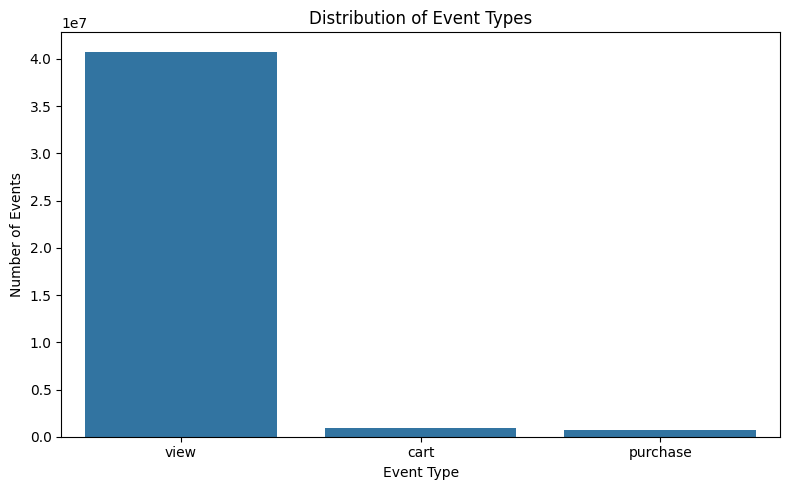

In [ ]:
event_counts = df["event_type"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=event_counts.index, y=event_counts.values)

plt.title("Distribution of Event Types")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.tight_layout()
plt.show()

### 3.2 Missing Value Analysis

**Purpose:** Visualizes the number of missing values in each feature.

**Observations:**
- Identifies features that require data cleaning.
- Features with many missing values may need imputation or removal.

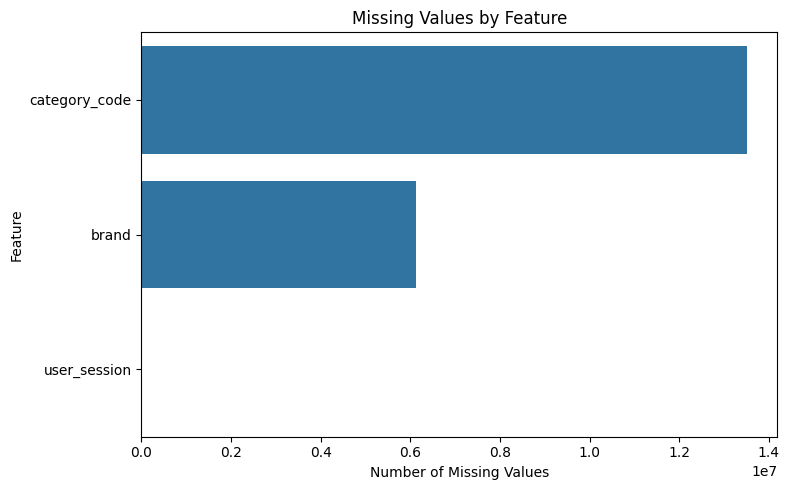

In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    plt.figure(figsize=(8, 5))
    sns.barplot(x=missing.values, y=missing.index)

    plt.title("Missing Values by Feature")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

### 3.3 Product Price Distribution

**Purpose:** Examines product prices using a histogram and KDE curve.

**Observations:**
- Shows the spread and concentration of product prices.
- Helps identify skewness and potential outliers.
- Uses a sample of up to 500,000 records for visualization.

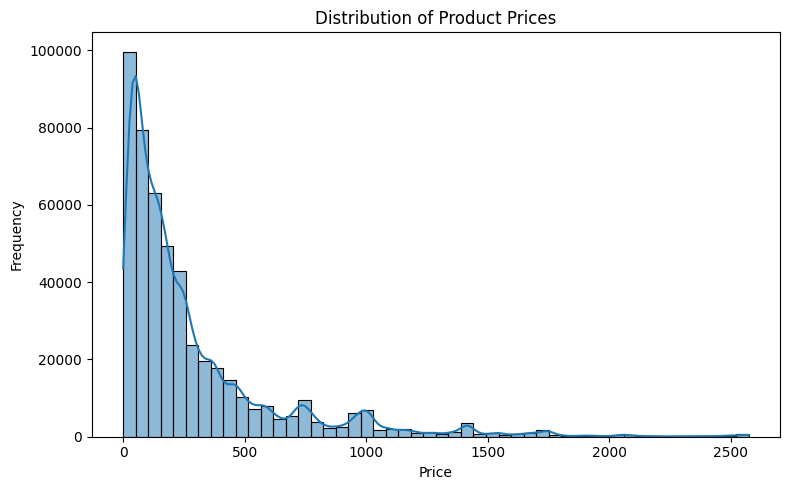

In [ ]:
price_sample = df["price"].dropna().sample(
    n=min(500000, df["price"].notna().sum()),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(8, 5))
sns.histplot(price_sample, bins=50, kde=True)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 3.4 Product, Category and Brand Diversity

**Purpose:** Counts unique products, categories, and brands.

**Observations:**
- Shows the diversity of products and brands.
- Helps understand the variety of items associated with user interactions.

In [ ]:
print("Unique Products:", df["product_id"].nunique())
print("Unique Categories:", df["category_id"].nunique())
print("Unique Brands:", df["brand"].nunique())

Unique Products: 166794
Unique Categories: 624
Unique Brands: 3444


### 3.5 Top 15 Categories by Events

**Purpose:** Displays the 15 categories with the highest number of events.

**Observations:**
- Identifies categories receiving the most user interactions.
- Highlights popular categories in the dataset.

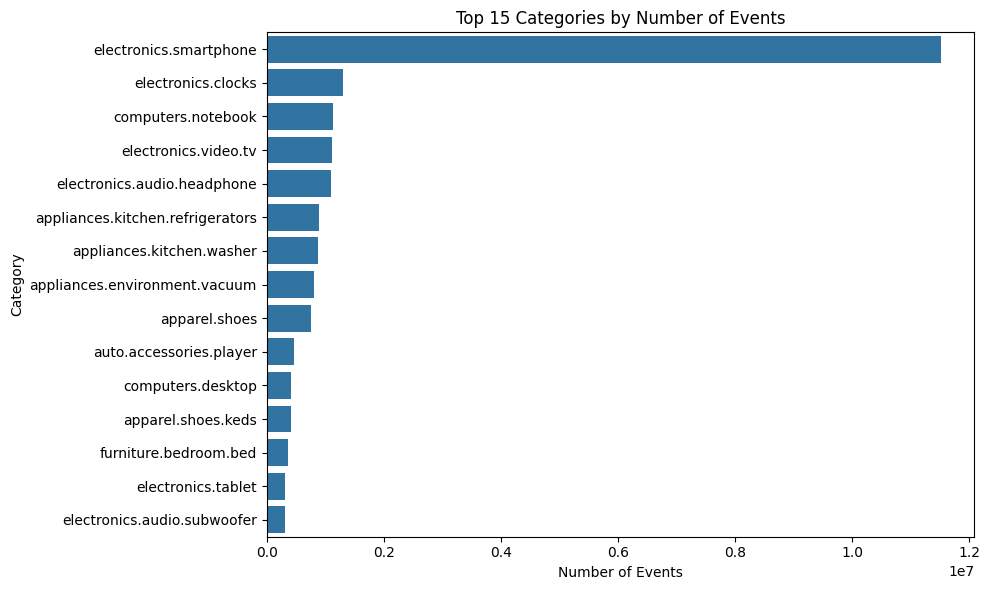

In [ ]:
top_categories = df["category_code"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_categories.values, y=top_categories.index)

plt.title("Top 15 Categories by Number of Events")
plt.xlabel("Number of Events")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### 3.6 Top 15 Brands by Events

**Purpose:** Displays the 15 brands associated with the highest number of events.

**Observations:**
- Identifies brands with the most recorded user interactions.
- Helps compare brand popularity based on event counts.

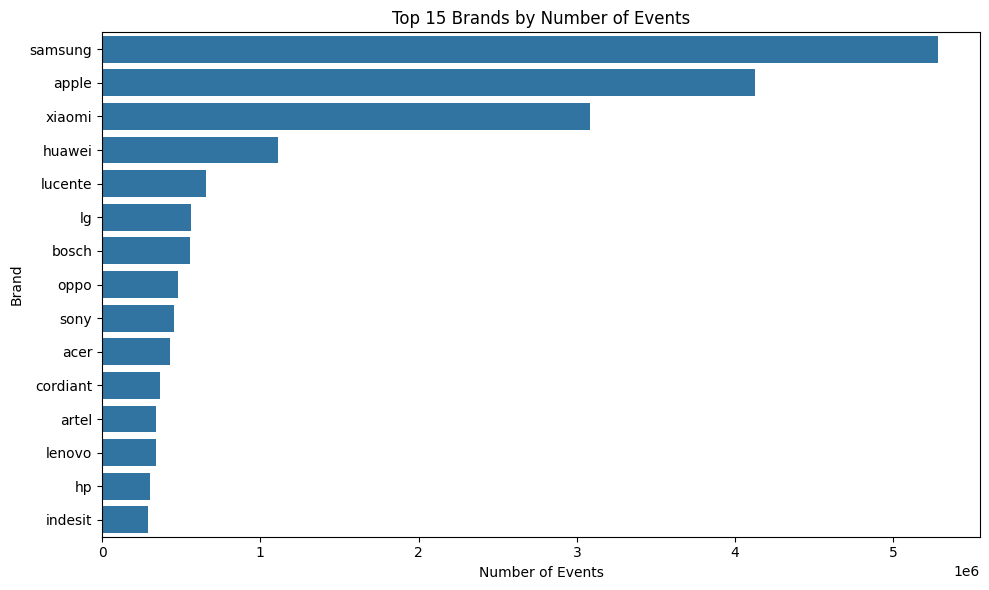

In [ ]:
top_brands = df["brand"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_brands.values, y=top_brands.index)

plt.title("Top 15 Brands by Number of Events")
plt.xlabel("Number of Events")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

### Observations
- **Event Distribution:** The chart shows which event types occur most frequently, helping identify dominant user interactions.
- **Missing Values:** Features with more missing values may require data cleaning or preprocessing.
- **Price Distribution:** The histogram reveals the price range, spread, skewness, and potential outliers.
- **Product Diversity:** Unique counts indicate the variety of products, categories, and brands in the dataset.
- **Category Popularity:** The top-category chart highlights categories receiving the most user interactions.
- **Brand Popularity:** The top-brand chart identifies brands associated with the highest number of events.

### 4.1 Data Cleaning

**Purpose:** Removes duplicate rows and records with missing user sessions.

**Observations:**
- Duplicate records are removed to avoid redundant data.
- Rows without `user_session` are removed because session-level analysis requires a valid session identifier.
- The remaining row count indicates the size of the cleaned dataset.

In [11]:
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove rows with missing user_session
df_clean = df_clean.dropna(subset=["user_session"]).copy()

print("Rows after cleaning:", len(df_clean))
print("Duplicate rows:", df_clean.duplicated().sum())
print("Missing sessions:", df_clean["user_session"].isna().sum())

Rows after cleaning: 42418542
Duplicate rows: 0
Missing sessions: 0


### 4.2 Price Validation

**Purpose:** Checks for events with zero or negative prices.

**Observations:**
- Zero-price events may represent free products or unusual records.
- Negative prices may indicate invalid data that requires investigation.
- These records are counted but not removed in this step.

In [12]:
print("Zero-price events:", (df_clean["price"] == 0).sum())
print("Negative-price events:", (df_clean["price"] < 0).sum())

Zero-price events: 68670
Negative-price events: 0


### 4.3 Helper Column Creation

**Purpose:** Converts timestamps and creates columns to identify views, cart additions, carted products, and viewed prices.

**Observations:**
- `is_view` and `is_cart` encode event types as binary indicators.
- `cart_product_id` records product IDs only for cart events.
- `view_price` stores prices only for view events.
- These columns simplify session-level feature aggregation.

In [13]:
df_clean["event_time"] = pd.to_datetime(
    df_clean["event_time"],
    errors="coerce"
)

df_clean["is_view"] = (
    df_clean["event_type"] == "view"
).astype("int8")

df_clean["is_cart"] = (
    df_clean["event_type"] == "cart"
).astype("int8")

df_clean["cart_product_id"] = df_clean["product_id"].where(
    df_clean["event_type"] == "cart"
)

df_clean["view_price"] = df_clean["price"].where(
    df_clean["event_type"] == "view"
)

### 4.4 Session-Level Feature Engineering

**Purpose:** Groups events by `user_session` and calculates behavioral features for each session.

**Observations:**
- Counts views, cart additions, and unique products and categories.
- Calculates average and maximum viewed-product prices.
- Records session start and end times.
- Converts event-level data into one row per session for further analysis.

In [14]:
print("Creating session-level features...")

session_features = (
    df_clean
    .groupby("user_session", sort=False)
    .agg(
        unique_products_viewed=("product_id", "nunique"),
        unique_categories_viewed=("category_id", "nunique"),
        total_views=("is_view", "sum"),
        cart_additions=("is_cart", "sum"),
        unique_products_carted=("cart_product_id", "nunique"),
        avg_price_viewed=("view_price", "mean"),
        max_price_viewed=("view_price", "max"),
        session_start=("event_time", "min"),
        session_end=("event_time", "max")
    )
    .reset_index()
)

display(session_features.head())

Creating session-level features...


,user_session,unique_products_viewed,unique_categories_viewed,total_views,cart_additions,unique_products_carted,avg_price_viewed,max_price_viewed,session_start,session_end
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,1,1,2,0,0,35.790000,35.79,2019-10-01 00:00:00+00:00,2019-10-01 00:00:15+00:00
1,9333dfbd-b87a-4708-9857-6336556b0fcc,1,1,1,0,0,33.200000,33.20,2019-10-01 00:00:00+00:00,2019-10-01 00:00:00+00:00
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,9,2,12,0,0,578.625000,882.88,2019-10-01 00:00:01+00:00,2019-10-01 00:07:03+00:00
3,7c90fc70-0e80-4590-96f3-13c02c18c713,5,1,7,0,0,582.668571,1512.78,2019-10-01 00:00:01+00:00,2019-10-01 00:03:17+00:00
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2,1,3,0,0,1525.853333,1747.79,2019-10-01 00:00:04+00:00,2019-10-01 00:00:43+00:00


### 4.5 Session Duration Calculation

**Purpose:** Calculates the duration of each session in minutes using its earliest and latest event timestamps.

**Observations:**
- Longer durations indicate more time between the first and last recorded events.
- A duration of zero may indicate that all recorded events occurred at the same timestamp.
- Invalid timestamps may result in missing duration values.

In [15]:
session_features["session_duration_minutes"] = (
    session_features["session_end"]
    - session_features["session_start"]
).dt.total_seconds() / 60

display(
    session_features[
        ["user_session", "session_start",
         "session_end", "session_duration_minutes"]
    ].head()
)

,user_session,session_start,session_end,session_duration_minutes
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01 00:00:00+00:00,2019-10-01 00:00:15+00:00,0.250000
1,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01 00:00:00+00:00,2019-10-01 00:00:00+00:00,0.000000
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01 00:00:01+00:00,2019-10-01 00:07:03+00:00,7.033333
3,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01 00:00:01+00:00,2019-10-01 00:03:17+00:00,3.266667
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01 00:00:04+00:00,2019-10-01 00:00:43+00:00,0.650000


### 4.6 Purchase Information

**Purpose:** Calculates the number of purchase events and their total recorded price for each session.

**Observations:**
- `purchase_count` indicates the number of purchase events in a session.
- `purchase_value` represents the sum of prices recorded for purchase events.
- Sessions without purchase events are excluded here and handled in the next step.

In [16]:
print("Creating purchase information...")

purchase_info = (
    df_clean[df_clean["event_type"] == "purchase"]
    .groupby("user_session", sort=False)
    .agg(
        purchase_count=("event_type", "size"),
        purchase_value=("price", "sum")
    )
    .reset_index()
)

display(purchase_info.head())

Creating purchase information...


,user_session,purchase_count,purchase_value
0,8187d148-3c41-46d4-b0c0-9c08cd9dc564,1,130.76
1,3c80f0d6-e9ec-4181-8c5c-837a30be2d68,2,804.67
2,0e5dfc4b-2a55-43e6-8c05-97e1f07fbb56,1,29.51
3,1dea3ee2-2ded-42e8-8e7a-4e2ad6ae942f,1,54.42
4,2af9b570-0942-4dcd-8f25-4d84fba82553,1,189.91


### 4.7 Merging Purchase Outcomes

**Purpose:** Combines purchase information with the session-level features using `user_session`.

**Observations:**
- Each session is matched with its purchase count and purchase value.
- A left join retains sessions even when they have no purchase records.
- Missing purchase information is handled in the next step.

In [17]:
session_features = session_features.merge(
    purchase_info,
    on="user_session",
    how="left"
)

display(session_features.head())

,user_session,unique_products_viewed,unique_categories_viewed,total_views,cart_additions,unique_products_carted,avg_price_viewed,max_price_viewed,session_start,session_end,session_duration_minutes,purchase_count,purchase_value
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,1,1,2,0,0,35.790000,35.79,2019-10-01 00:00:00+00:00,2019-10-01 00:00:15+00:00,0.250000,NaN,NaN
1,9333dfbd-b87a-4708-9857-6336556b0fcc,1,1,1,0,0,33.200000,33.20,2019-10-01 00:00:00+00:00,2019-10-01 00:00:00+00:00,0.000000,NaN,NaN
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,9,2,12,0,0,578.625000,882.88,2019-10-01 00:00:01+00:00,2019-10-01 00:07:03+00:00,7.033333,NaN,NaN
3,7c90fc70-0e80-4590-96f3-13c02c18c713,5,1,7,0,0,582.668571,1512.78,2019-10-01 00:00:01+00:00,2019-10-01 00:03:17+00:00,3.266667,NaN,NaN
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2,1,3,0,0,1525.853333,1747.79,2019-10-01 00:00:04+00:00,2019-10-01 00:00:43+00:00,0.650000,NaN,NaN


### 4.8 Handling Sessions Without Purchases

**Purpose:** Replaces missing purchase counts and values with zero.

**Observations:**
- Sessions without purchase events receive a purchase count of zero.
- Their purchase value is set to zero.
- This prepares the data for creating the conversion label.

In [18]:
session_features["purchase_count"] = (
    session_features["purchase_count"].fillna(0)
)

session_features["purchase_value"] = (
    session_features["purchase_value"].fillna(0)
)

display(
    session_features[
        ["user_session", "purchase_count", "purchase_value"]
    ].head()
)

,user_session,purchase_count,purchase_value
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,0.0,0.0
1,9333dfbd-b87a-4708-9857-6336556b0fcc,0.0,0.0
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,0.0,0.0
3,7c90fc70-0e80-4590-96f3-13c02c18c713,0.0,0.0
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,0.0,0.0


### 4.9 Conversion Label Creation

**Purpose:** Creates a binary target column indicating whether a session resulted in a purchase.

**Observations:**
- `converted = 1` indicates at least one purchase event.
- `converted = 0` indicates no purchase event.
- This label can support session conversion analysis and predictive modeling.

In [19]:
session_features["converted"] = (
    session_features["purchase_count"] > 0
).astype(int)

print("Conversion distribution:")
print(session_features["converted"].value_counts())

display(session_features.head())

Conversion distribution:
converted
0    8614861
1     629560
Name: count, dtype: int64


,user_session,unique_products_viewed,unique_categories_viewed,total_views,cart_additions,unique_products_carted,avg_price_viewed,max_price_viewed,session_start,session_end,session_duration_minutes,purchase_count,purchase_value,converted
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,1,1,2,0,0,35.790000,35.79,2019-10-01 00:00:00+00:00,2019-10-01 00:00:15+00:00,0.250000,0.0,0.0,0
1,9333dfbd-b87a-4708-9857-6336556b0fcc,1,1,1,0,0,33.200000,33.20,2019-10-01 00:00:00+00:00,2019-10-01 00:00:00+00:00,0.000000,0.0,0.0,0
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,9,2,12,0,0,578.625000,882.88,2019-10-01 00:00:01+00:00,2019-10-01 00:07:03+00:00,7.033333,0.0,0.0,0
3,7c90fc70-0e80-4590-96f3-13c02c18c713,5,1,7,0,0,582.668571,1512.78,2019-10-01 00:00:01+00:00,2019-10-01 00:03:17+00:00,3.266667,0.0,0.0,0
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2,1,3,0,0,1525.853333,1747.79,2019-10-01 00:00:04+00:00,2019-10-01 00:00:43+00:00,0.650000,0.0,0.0,0


### 4.10 Final Dataset Inspection

**Purpose:** Checks the dimensions and sample records of the engineered session-level dataset.

**Observations:**
- Each row represents a user session.
- The columns contain behavioral features, session duration, purchase information, and the conversion label.
- The resulting dataset is prepared for further analysis and modeling.

In [20]:
print("Session-level shape:", session_features.shape)

display(session_features.head())

Session-level shape: (9244421, 14)


,user_session,unique_products_viewed,unique_categories_viewed,total_views,cart_additions,unique_products_carted,avg_price_viewed,max_price_viewed,session_start,session_end,session_duration_minutes,purchase_count,purchase_value,converted
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,1,1,2,0,0,35.790000,35.79,2019-10-01 00:00:00+00:00,2019-10-01 00:00:15+00:00,0.250000,0.0,0.0,0
1,9333dfbd-b87a-4708-9857-6336556b0fcc,1,1,1,0,0,33.200000,33.20,2019-10-01 00:00:00+00:00,2019-10-01 00:00:00+00:00,0.000000,0.0,0.0,0
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,9,2,12,0,0,578.625000,882.88,2019-10-01 00:00:01+00:00,2019-10-01 00:07:03+00:00,7.033333,0.0,0.0,0
3,7c90fc70-0e80-4590-96f3-13c02c18c713,5,1,7,0,0,582.668571,1512.78,2019-10-01 00:00:01+00:00,2019-10-01 00:03:17+00:00,3.266667,0.0,0.0,0
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2,1,3,0,0,1525.853333,1747.79,2019-10-01 00:00:04+00:00,2019-10-01 00:00:43+00:00,0.650000,0.0,0.0,0


### 5.1 Clustering Feature Selection

**Purpose:** Selects session-level behavioral features for clustering.

**Observations:**
- Includes browsing activity, cart additions, product prices, and session duration.
- Creates `X_cluster` containing the selected features for clustering algorithms.
- Checks the dataset dimensions and missing values before preprocessing.
- Missing values must be handled before scaling and clustering.

In [21]:
# ============================================================
# Clustering Feature Selection
# ============================================================

cluster_features = [
    "unique_products_viewed",
    "unique_categories_viewed",
    "total_views",
    "cart_additions",
    "unique_products_carted",
    "avg_price_viewed",
    "max_price_viewed",
    "session_duration_minutes"
]

X_cluster = session_features[cluster_features].copy()

print("Clustering data shape:", X_cluster.shape)
print("\nMissing values:")
print(X_cluster.isna().sum())

Clustering data shape: (9244421, 8)

Missing values:
unique_products_viewed         0
unique_categories_viewed       0
total_views                    0
cart_additions                 0
unique_products_carted         0
avg_price_viewed            1768
max_price_viewed            1768
session_duration_minutes       0
dtype: int64


### 5.2 Handling Missing and Infinite Values

**Purpose:** Replaces infinite values with missing values and fills all missing values with zero.

**Observations:**
- Converts positive and negative infinity to `NaN`.
- Checks missing values before and after filling.
- Replaces missing values with zero to prepare the data for clustering.
- Ensures no missing values remain in `X_cluster`.

In [26]:
# ============================================================
# Handle Missing and Infinite Values
# ============================================================

X_cluster = X_cluster.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Missing values before filling:")
print(X_cluster.isna().sum())

X_cluster = X_cluster.fillna(0)

print("\nMissing values after filling:")
print(X_cluster.isna().sum())

Missing values before filling:
unique_products_viewed         0
unique_categories_viewed       0
total_views                    0
cart_additions                 0
unique_products_carted         0
avg_price_viewed            1768
max_price_viewed            1768
session_duration_minutes       0
dtype: int64

Missing values after filling:
unique_products_viewed      0
unique_categories_viewed    0
total_views                 0
cart_additions              0
unique_products_carted      0
avg_price_viewed            0
max_price_viewed            0
session_duration_minutes    0
dtype: int64


### 5.3 Feature Scaling

**Purpose:** Standardizes the clustering features using `StandardScaler`.

**Observations:**
- Transforms features to have approximately zero mean and unit variance.
- Prevents features with larger numerical ranges from dominating distance-based clustering.
- Stores the scaled data in `X_scaled` for use in clustering algorithms.
- The output shape should match the input shape.

In [27]:
# ============================================================
# Feature Scaling
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (9244421, 8)


### 5.4 MiniBatchKMeans Clustering

**Purpose:** Groups user sessions into four clusters using MiniBatchKMeans.

**Observations:**
- Uses batches of 2,048 samples to improve clustering efficiency on large datasets.
- Assigns sessions to clusters based on their scaled behavioral features.
- `random_state=42` ensures reproducibility, while `n_init=10` runs multiple initializations.
- The resulting clusters can help identify different user browsing and purchasing behavior patterns.

In [28]:
from sklearn.cluster import MiniBatchKMeans

In [29]:
# ============================================================
# MiniBatchKMeans Clustering
# ============================================================

K = 4

mini_kmeans = MiniBatchKMeans(
    n_clusters=K,
    batch_size=2048,
    random_state=RANDOM_STATE,
    n_init=10
)

mini_kmeans.fit(X_scaled)

print("MiniBatchKMeans training completed.")
print("Number of clusters:", K)

MiniBatchKMeans training completed.
Number of clusters: 4


In [30]:
# ============================================================
# Assign Cluster Labels to ALL Sessions
# ============================================================

session_features["cluster"] = mini_kmeans.predict(X_scaled)

print("Cluster assignment completed.")

print("\nCluster distribution:")
print(
    session_features["cluster"]
    .value_counts()
    .sort_index()
)

Cluster assignment completed.

Cluster distribution:
cluster
0    1431933
1    6770409
2     486228
3     555851
Name: count, dtype: int64


### 5.5 Elbow Method for Optimal K

**Purpose:** Evaluates different cluster counts (K = 2 to 8) using MiniBatchKMeans and plots their inertia values.

**Observations:**
- Inertia measures the sum of squared distances between data points and their assigned cluster centers.
- Inertia generally decreases as the number of clusters increases.
- The elbow point indicates a possible optimal K, where further reductions in inertia become less significant.
- The optimal K should be selected by identifying the bend in the plotted curve.

Training MiniBatchKMeans for K = 2...
Training MiniBatchKMeans for K = 3...
Training MiniBatchKMeans for K = 4...
Training MiniBatchKMeans for K = 5...
Training MiniBatchKMeans for K = 6...
Training MiniBatchKMeans for K = 7...
Training MiniBatchKMeans for K = 8...


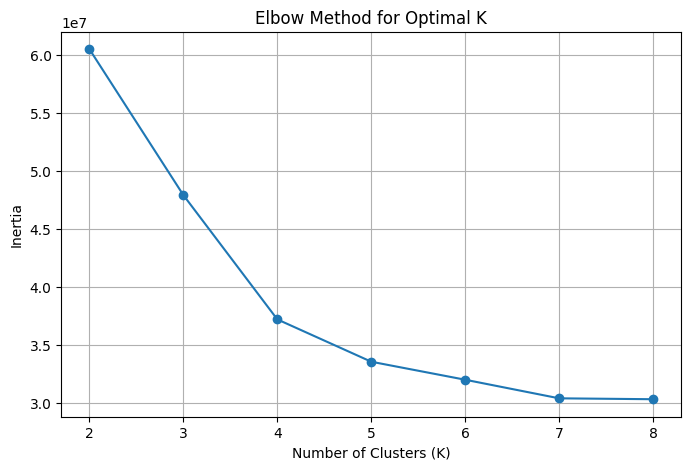

In [31]:
# ============================================================
# Elbow Method for Optimal Number of Clusters
# ============================================================

k_values = range(2, 9)
inertias = []

for k in k_values:
    print(f"Training MiniBatchKMeans for K = {k}...")
    
    model = MiniBatchKMeans(
        n_clusters=k,
        batch_size=2048,
        random_state=RANDOM_STATE,
        n_init=10
    )
    
    model.fit(X_scaled)
    inertias.append(model.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()

### 5.6 Clustering Evaluation Metrics

**Purpose:** Evaluates MiniBatchKMeans clustering for K = 2 to 8 using three metrics on a representative sample of 50,000 records.

**Observations:**
- **Silhouette Score:** Higher values indicate better-separated and more cohesive clusters.
- **Davies-Bouldin Index:** Lower values indicate better cluster separation.
- **Calinski-Harabasz Index:** Higher values generally indicate better-defined clusters.
- Models are trained on the full dataset, while metrics are calculated on the sample to reduce computation time.
- The results help compare cluster counts and select a suitable K.

In [32]:
# ============================================================
# Clustering Evaluation Metrics
# ============================================================

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Representative sample for metric evaluation
METRIC_SAMPLE_SIZE = 50000

rng = np.random.RandomState(RANDOM_STATE)

sample_indices = rng.choice(
    X_scaled.shape[0],
    size=METRIC_SAMPLE_SIZE,
    replace=False
)

X_metric = X_scaled[sample_indices]

print("Metric evaluation sample shape:", X_metric.shape)


# Store results
evaluation_results = []

k_values = range(2, 9)

for k in k_values:

    print(f"\nEvaluating K = {k}...")

    model = MiniBatchKMeans(
        n_clusters=k,
        batch_size=2048,
        random_state=RANDOM_STATE,
        n_init=10
    )

    # Train on ALL data
    model.fit(X_scaled)

    # Predict only the evaluation sample
    sample_labels = model.predict(X_metric)

    # Calculate clustering metrics
    silhouette = silhouette_score(
        X_metric,
        sample_labels
    )

    davies_bouldin = davies_bouldin_score(
        X_metric,
        sample_labels
    )

    calinski_harabasz = calinski_harabasz_score(
        X_metric,
        sample_labels
    )

    evaluation_results.append({
        "K": k,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": davies_bouldin,
        "Calinski-Harabasz Index": calinski_harabasz
    })


# Convert results to DataFrame
evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df)

Metric evaluation sample shape: (50000, 8)

Evaluating K = 2...

Evaluating K = 3...

Evaluating K = 4...

Evaluating K = 5...

Evaluating K = 6...

Evaluating K = 7...

Evaluating K = 8...


,K,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,2,0.608106,0.861147,11053.099774
1,3,0.531642,1.183875,13434.717283
2,4,0.542446,0.913615,15990.929344
3,5,0.527272,1.030819,14528.015533
4,6,0.401915,1.043020,12765.888640
5,7,0.332270,1.116274,11620.660104
6,8,0.323461,1.201806,10195.332853


### 5.7 Cluster Profiling

**Purpose:** Calculates the average behavioral features for each cluster to understand differences between user groups.

**Observations:**
- Compares browsing activity, cart additions, product diversity, prices, and session duration across clusters.
- Helps identify clusters with high engagement or frequent cart activity.
- Reveals behavioral patterns that can support customer segmentation.
- Actual cluster characteristics must be interpreted from the generated profile table.

In [33]:
# ============================================================
# Cluster Profiling
# ============================================================

cluster_profile = session_features.groupby("cluster")[cluster_features].mean()

display(cluster_profile)

,unique_products_viewed,unique_categories_viewed,total_views,cart_additions,unique_products_carted,avg_price_viewed,max_price_viewed,session_duration_minutes
cluster,,,,,,,,
0,2.699746,1.217198,3.621454,0.003778,0.003772,963.201215,1221.721010,16.668992
1,2.195785,1.202143,3.138821,0.000000,0.000000,180.539816,217.254778,16.542822
2,15.586060,3.931604,23.424081,0.030144,0.025642,232.618172,683.058146,37.430836
3,2.654209,1.225309,5.309157,1.580233,1.098024,332.883100,414.657132,11.615137


### 5.8 Cluster Size Distribution

**Purpose:** Calculates the number and percentage of sessions assigned to each cluster.

**Observations:**
- Shows how sessions are distributed across clusters.
- Identifies the largest and smallest clusters.
- Helps determine whether clusters are balanced or unevenly distributed.
- Cluster percentages indicate each group's proportion of total sessions.

In [34]:
# Cluster size and percentage
cluster_sizes = session_features["cluster"].value_counts().sort_index()

cluster_percentage = (
    session_features["cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

cluster_summary = pd.DataFrame({
    "Sessions": cluster_sizes,
    "Percentage": cluster_percentage.round(2)
})

display(cluster_summary)

,Sessions,Percentage
cluster,,
0,1431933,15.49
1,6770409,73.24
2,486228,5.26
3,555851,6.01


### 5.9 Detailed Cluster Profiling

**Purpose:** Calculates the mean of each behavioral feature for every cluster and rounds the results to two decimal places.

**Observations:**
- Displays all columns to make the cluster profiles easier to compare.
- Highlights differences in browsing activity, cart additions, product prices, and session duration.
- Helps interpret the behavioral characteristics of each cluster.
- Actual cluster patterns must be identified from the resulting table.

In [35]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

cluster_profile = (
    session_features
    .groupby("cluster")[cluster_features]
    .mean()
    .round(2)
)

display(cluster_profile)

,unique_products_viewed,unique_categories_viewed,total_views,cart_additions,unique_products_carted,avg_price_viewed,max_price_viewed,session_duration_minutes
cluster,,,,,,,,
0,2.70,1.22,3.62,0.00,0.00,963.20,1221.72,16.67
1,2.20,1.20,3.14,0.00,0.00,180.54,217.25,16.54
2,15.59,3.93,23.42,0.03,0.03,232.62,683.06,37.43
3,2.65,1.23,5.31,1.58,1.10,332.88,414.66,11.62


### 5.10 PCA 2D Visualization of Clusters

**Purpose:** Reduces the scaled features to two principal components and visualizes the clusters in a scatter plot.

**Observations:**
- PCA projects the eight features into two dimensions for visualization.
- Each point represents a session, colored according to its cluster label.
- The explained variance ratio indicates how much information each component captures.
- Clearly separated groups suggest distinct behavioral patterns, while overlapping groups indicate similarities.
- The plot uses a sample of up to 50,000 sessions to reduce visualization time.

Explained variance ratio:
[0.29687862 0.22431673]
Total explained variance: 0.5211953483919343


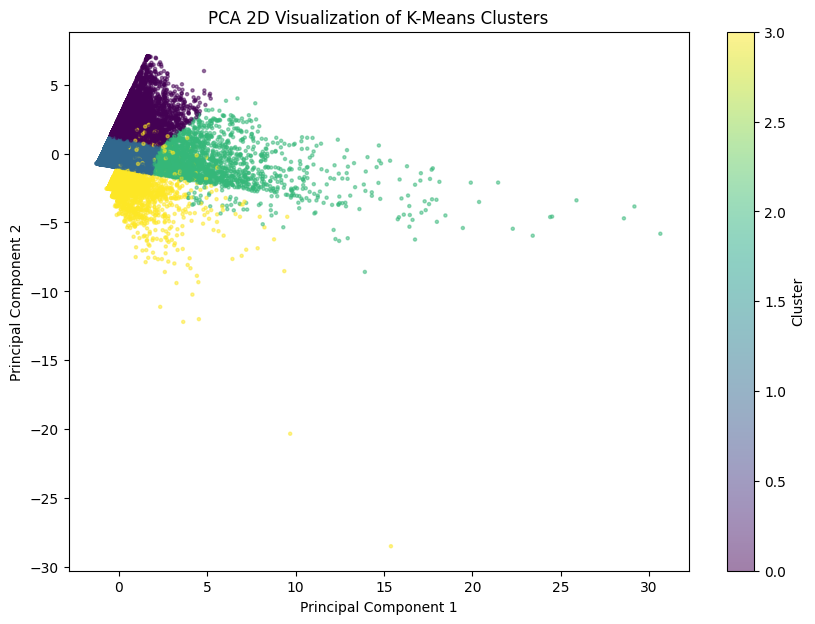

In [36]:
# ============================================================
# PCA 2D Visualization
# ============================================================

from sklearn.decomposition import PCA

# Sample sessions for visualization
PCA_SAMPLE_SIZE = 50000

rng = np.random.RandomState(RANDOM_STATE)

pca_indices = rng.choice(
    X_scaled.shape[0],
    size=PCA_SAMPLE_SIZE,
    replace=False
)

X_pca_sample = X_scaled[pca_indices]
labels_pca = session_features["cluster"].values[pca_indices]

# PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)

X_pca = pca.fit_transform(X_pca_sample)

print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total explained variance:",
      pca.explained_variance_ratio_.sum())


# Plot
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_pca,
    s=5,
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA 2D Visualization of K-Means Clusters")
plt.colorbar(scatter, label="Cluster")

plt.show()

### 5.11 t-SNE Visualization of Clusters

**Purpose:** Reduces the scaled features to two dimensions using t-SNE to visualize cluster patterns.

**Observations:**
- Each point represents a session, colored according to its assigned cluster.
- Nearby points represent sessions with similar feature patterns in the t-SNE projection.
- Distinct groups suggest differences in session behavior, while overlapping groups suggest similarities.
- Uses a sample of 10,000 sessions to reduce computation time.
- Unlike PCA, t-SNE focuses on preserving local similarities and does not directly provide explained variance.

t-SNE sample shape: (10000, 8)


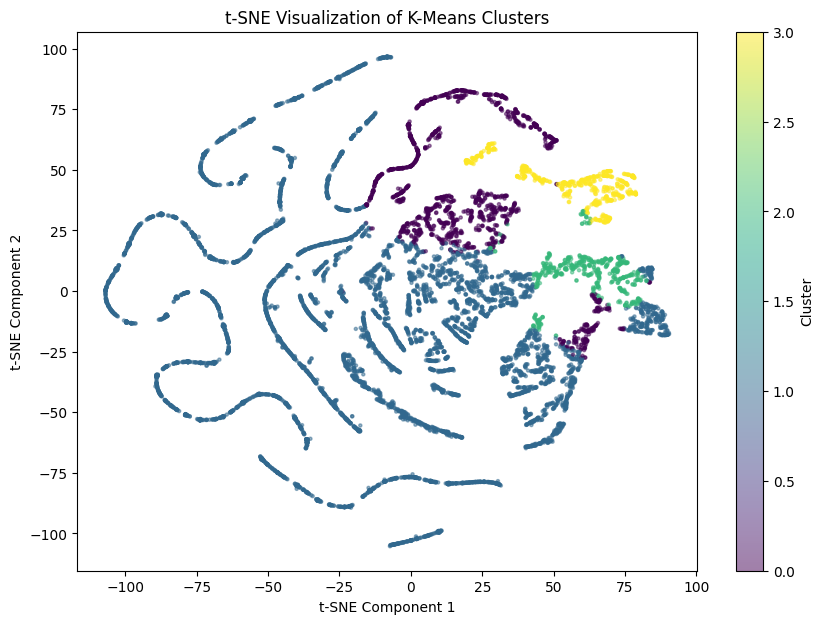

In [37]:
# ============================================================
# t-SNE Visualization
# ============================================================

from sklearn.manifold import TSNE

TSNE_SAMPLE_SIZE = 10000

rng = np.random.RandomState(RANDOM_STATE)

tsne_indices = rng.choice(
    X_scaled.shape[0],
    size=TSNE_SAMPLE_SIZE,
    replace=False
)

X_tsne_sample = X_scaled[tsne_indices]
labels_tsne = session_features["cluster"].values[tsne_indices]

print("t-SNE sample shape:", X_tsne_sample.shape)

# t-SNE
tsne = TSNE(
    n_components=2,
    random_state=RANDOM_STATE,
    perplexity=30,
    max_iter=1000
)

X_tsne = tsne.fit_transform(X_tsne_sample)

# Plot
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=labels_tsne,
    s=5,
    alpha=0.5
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("t-SNE Visualization of K-Means Clusters")
plt.colorbar(scatter, label="Cluster")

plt.show()